In [1]:
# ================================================================
# 08 — SHAP Analyse: Modell B (log laufzeittage)
# ================================================================

import sys, os, time, warnings, joblib
sys.path.append('..')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

from src.data.preprocessing import (
    FEATURE_COLS, TARGET_PRICE, TARGET_DURATION,
    load_parquet, prepare_features, prepare_target_price, stratified_sample,
    prepare_features_for_trees,
)

RANDOM_STATE = 42
SAMPLE_FRAC  = 0.05
DATA_PATH    = '../data/processed/AUTO_final_enriched.parquet'
FIG_DIR      = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)

In [2]:
cols_needed = list(set(FEATURE_COLS + [TARGET_DURATION, "ajahr"]))
df_full = pd.read_parquet(DATA_PATH, columns=cols_needed)
print(f"df_full: {df_full.memory_usage(deep=True).sum() / 1e9:.2f} GB")

df_full: 4.92 GB


In [3]:
#df_full   = load_parquet(DATA_PATH)
from src.data.preprocessing import prepare_target_duration


df_sample = stratified_sample(df_full, frac=SAMPLE_FRAC, seed=RANDOM_STATE)

X = prepare_features(df_sample)
y = prepare_target_duration(df_sample)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df_sample["ajahr"],
)

# XGBoost kann keine str-Spalten verarbeiten -> Ordinal-Encoding (fit nur auf Train, kein Leakage)
X_train, X_test, ord_encoder = prepare_features_for_trees(X_train, X_test)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Train: (460218, 32) | Test: (115055, 32)


In [5]:
xgb = joblib.load("../models/xgb_tuned_duration.joblib")
lgbm = joblib.load("../models/lgbm_tuned_duration.joblib")

In [9]:
from scipy.stats import spearmanr, weightedtau

imp_price = pd.read_parquet('../data/processed/importance_xgb_lgbm_price.parquet')
imp_dur   = pd.read_parquet('../data/processed/importance_xgb_lgbm_duration.parquet')

rho_p, _ = spearmanr(imp_price['XGBoost'].rank(), imp_price['LightGBM'].rank())
tau_p, _ = weightedtau(imp_price['XGBoost'], imp_price['LightGBM'])
rho_d, _ = spearmanr(imp_dur['XGBoost'].rank(), imp_dur['LightGBM'].rank())
tau_d, _ = weightedtau(imp_dur['XGBoost'], imp_dur['LightGBM'])

In [6]:
X_shap_dur_imp = X_test.sample(n=min(10_000, len(X_test)), random_state=RANDOM_STATE)

shap_xgb_dur  = shap.TreeExplainer(xgb).shap_values(X_shap_dur_imp)
shap_lgbm_dur = shap.TreeExplainer(lgbm).shap_values(X_shap_dur_imp)

imp_dur = pd.DataFrame({
    'XGBoost':  pd.Series(np.abs(shap_xgb_dur).mean(axis=0),  index=X_shap_dur_imp.columns),
    'LightGBM': pd.Series(np.abs(shap_lgbm_dur).mean(axis=0), index=X_shap_dur_imp.columns),
})

rho_dur, p_dur = spearmanr(imp_dur['XGBoost'].rank(), imp_dur['LightGBM'].rank())
tau_dur, _     = weightedtau(imp_dur['XGBoost'], imp_dur['LightGBM'])
print(f"Spearman ρ = {rho_dur:.3f}  (p = {p_dur:.2e})")
print(f"Weighted Kendall's τ = {tau_dur:.3f}")

imp_dur.to_parquet('../data/processed/importance_xgb_lgbm_duration.parquet')

NameError: name 'spearmanr' is not defined

In [7]:
imp_dur.to_parquet('../data/processed/importance_xgb_lgbm_duration.parquet')

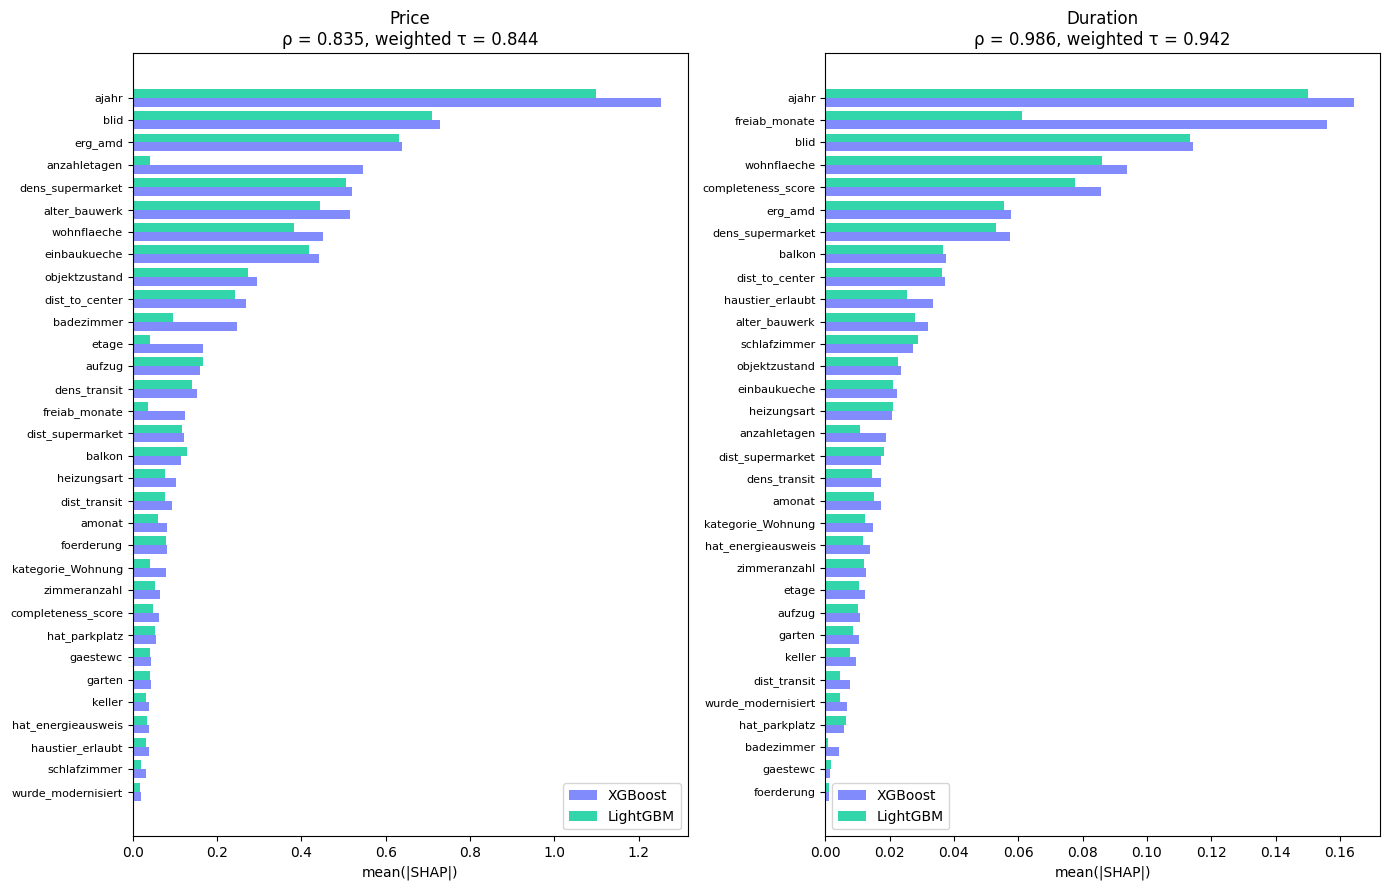

In [10]:
imp_price = pd.read_parquet('../data/processed/importance_xgb_lgbm_price.parquet')
imp_dur   = pd.read_parquet('../data/processed/importance_xgb_lgbm_duration.parquet')

rho_p, _ = spearmanr(imp_price['XGBoost'].rank(), imp_price['LightGBM'].rank())
tau_p, _ = weightedtau(imp_price['XGBoost'], imp_price['LightGBM'])
rho_d, _ = spearmanr(imp_dur['XGBoost'].rank(), imp_dur['LightGBM'].rank())
tau_d, _ = weightedtau(imp_dur['XGBoost'], imp_dur['LightGBM'])

fig, axes = plt.subplots(1, 2, figsize=(14, 9))

for ax, imp_t, rho_t, tau_t, label in [
    (axes[0], imp_price, rho_p, tau_p, 'Price'),
    (axes[1], imp_dur,   rho_d, tau_d, 'Duration'),
]:
    imp_sorted = imp_t.sort_values('XGBoost', ascending=True)
    y_pos = np.arange(len(imp_sorted))
    ax.barh(y_pos - 0.2, imp_sorted['XGBoost'],  height=0.4, label='XGBoost',  color='#636EFA', alpha=0.8)
    ax.barh(y_pos + 0.2, imp_sorted['LightGBM'], height=0.4, label='LightGBM', color='#00CC96', alpha=0.8)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(imp_sorted.index, fontsize=8)
    ax.set_xlabel('mean(|SHAP|)')
    ax.set_title(f'{label}\nρ = {rho_t:.3f}, weighted τ = {tau_t:.3f}')
    ax.legend()

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/shap_importance_xgb_vs_lgbm_combined.png', dpi=150, bbox_inches='tight')
plt.show()

Spearman ρ = 0.984  (p = 3.93e-24)


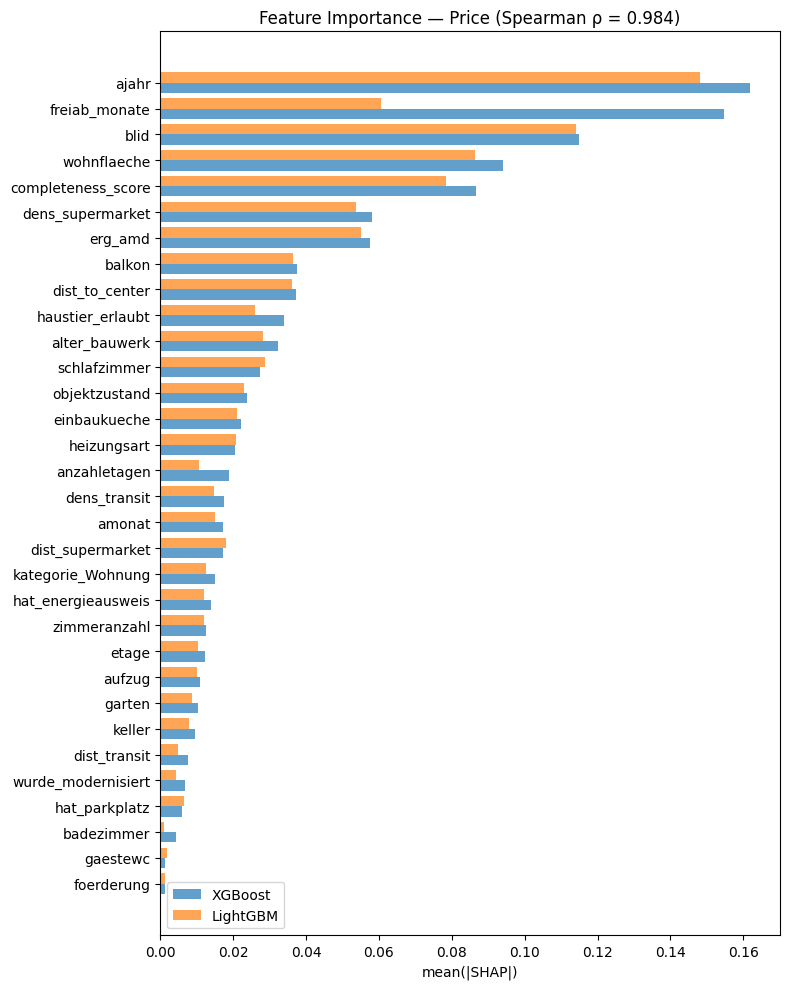

In [ ]:
# --- SHAP für beide Modelle ---
from scipy.stats import spearmanr

X_shap = X_test.sample(n=min(5_000, len(X_test)), random_state=RANDOM_STATE)

shap_xgb  = shap.TreeExplainer(xgb).shap_values(X_shap)
shap_lgbm = shap.TreeExplainer(lgbm).shap_values(X_shap)

# --- Importance-Ranking vergleichen ---
imp = pd.DataFrame({
    'XGBoost':  pd.Series(np.abs(shap_xgb).mean(axis=0),  index=X_shap.columns),
    'LightGBM': pd.Series(np.abs(shap_lgbm).mean(axis=0), index=X_shap.columns),
})

rho, p = spearmanr(imp['XGBoost'].rank(), imp['LightGBM'].rank())
print(f"Spearman ρ = {rho:.3f}  (p = {p:.2e})")

# --- Visueller Check ---
imp_sorted = imp.sort_values('XGBoost', ascending=True)
fig, ax = plt.subplots(figsize=(8, 10))
y_pos = range(len(imp_sorted))
ax.barh(y_pos, imp_sorted['XGBoost'], height=0.4, label='XGBoost', alpha=0.7)
ax.barh([y + 0.4 for y in y_pos], imp_sorted['LightGBM'], height=0.4, label='LightGBM', alpha=0.7)
ax.set_yticks([y + 0.2 for y in y_pos])
ax.set_yticklabels(imp_sorted.index)
ax.set_xlabel('mean(|SHAP|)')
ax.set_title(f'Feature Importance — Duration (Spearman ρ = {rho:.3f})')
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/shap_importance_xgb_vs_lgbm_duration.png", dpi=150, bbox_inches="tight")
plt.show()

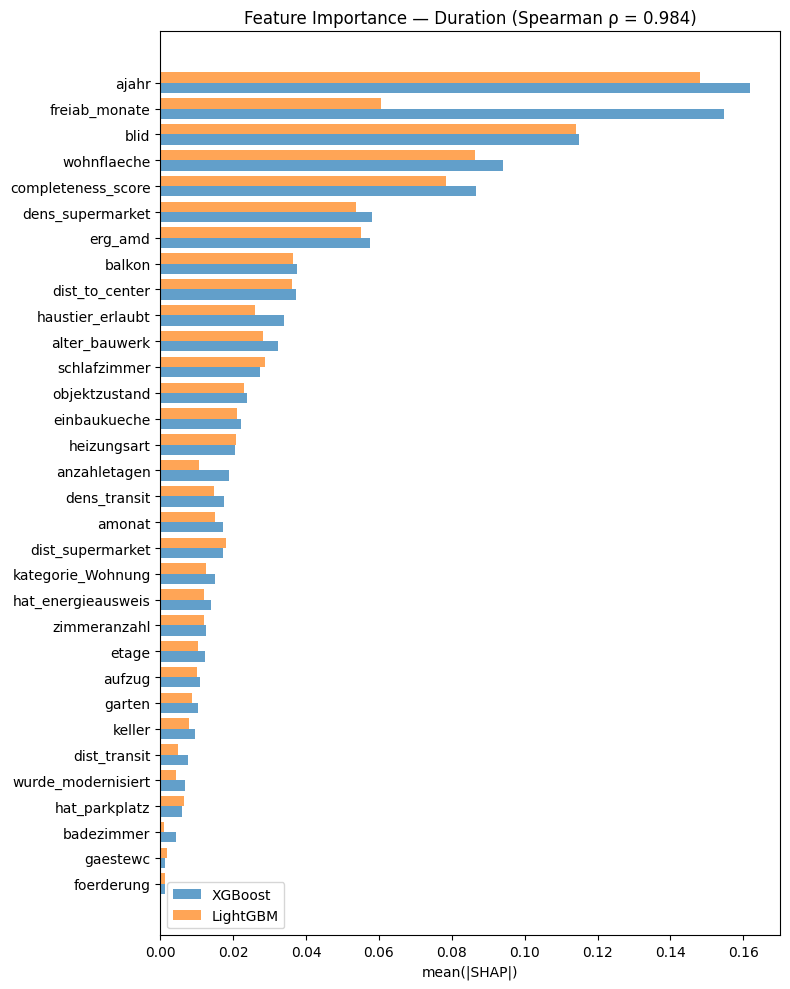

In [ ]:
# --- Visueller Check ---
imp_sorted = imp.sort_values('XGBoost', ascending=True)
fig, ax = plt.subplots(figsize=(8, 10))
y_pos = range(len(imp_sorted))
ax.barh(y_pos, imp_sorted['XGBoost'], height=0.4, label='XGBoost', alpha=0.7)
ax.barh([y + 0.4 for y in y_pos], imp_sorted['LightGBM'], height=0.4, label='LightGBM', alpha=0.7)
ax.set_yticks([y + 0.2 for y in y_pos])
ax.set_yticklabels(imp_sorted.index)
ax.set_xlabel('mean(|SHAP|)')
ax.set_title(f'Feature Importance — Duration (Spearman ρ = {rho:.3f})')
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/shap_importance_xgb_vs_lgbm_duration.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# ── Pfade ──────────────────────────────────────────────────────────────────
SHAPES_DIR = '../data/processed'
MODELS_DIR = '../models'
SHAPE_FILES = {
    ('EBM',   'duration'):    'shapes_ebm_duration.parquet',
}

# ── Laden ──────────────────────────────────────────────────────────────────
shapes = {}
for (model, target), fname in SHAPE_FILES.items():
    path = os.path.join(SHAPES_DIR, fname)
    if os.path.exists(path):
        shapes[(model, target)] = pd.read_parquet(path)
        n_feat = shapes[(model, target)]['feature'].nunique()
        print(f'  ✅ {fname}  ({n_feat} Features)')
    else:
        shapes[(model, target)] = None
        print(f'  ⏳ {fname} nicht vorhanden — NB03/04 zuerst ausführen')

missing = [k for k, v in shapes.items() if v is None]
if missing:
    print(f'\n⚠️  {len(missing)} Datei(en) fehlen. Nur verfügbare Daten werden analysiert.')
else:
    print('\n✅ Alle Shape-Parquets geladen — ready für Analyse.')

  ✅ shapes_ebm_duration.parquet  (32 Features)

✅ Alle Shape-Parquets geladen — ready für Analyse.


EBM Main Effects: 32 | Interaktionen: 8
Anteil Interaktions-Importance: 11.7%

Spearman ρ (EBM vs. XGBoost, Modell A): 0.882  (p = 2.69e-11)


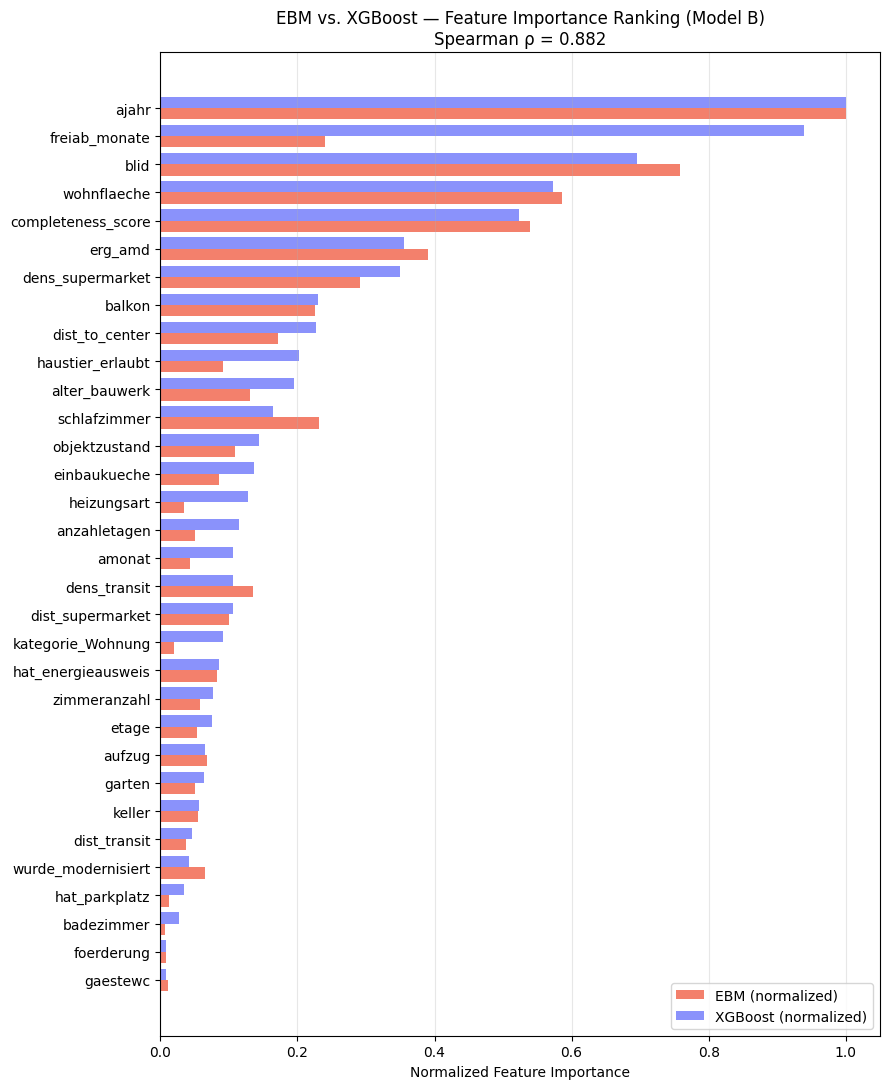

In [10]:
# ================================================================
# Cross-Method Ranking-Vergleich: EBM vs. XGBoost (Modell B Preis)
# ================================================================

# --- 1) EBM Importance aus explain_global() ---
ebm_model = joblib.load(os.path.join(MODELS_DIR, 'ebm_tuned_duration.joblib'))
ebm_data = ebm_model.explain_global().data()

ebm_imp = pd.Series(ebm_data['scores'], index=ebm_data['names'])
main_mask = ~ebm_imp.index.str.contains(' & ', regex=False)
ebm_main = ebm_imp[main_mask]
ebm_inter = ebm_imp[~main_mask]

print(f"EBM Main Effects: {len(ebm_main)} | Interaktionen: {len(ebm_inter)}")
print(f"Anteil Interaktions-Importance: {ebm_inter.sum() / ebm_imp.sum():.1%}")

# --- 2) XGBoost SHAP Importance ---
xgb_model = joblib.load(os.path.join(MODELS_DIR, 'xgb_tuned_duration.joblib'))

df_full = load_parquet('../data/processed/AUTO_final_enriched.parquet')
df_s    = stratified_sample(df_full, frac=0.05, seed=42)
X       = prepare_features(df_s)
X_train, X_test = train_test_split(
    X, test_size=0.20, random_state=42, stratify=df_s['ajahr']
)[:2]
X_train, X_test, _ = prepare_features_for_trees(X_train, X_test)

X_shap = X_test.sample(n=20_000, random_state=42)
shap_vals = shap.TreeExplainer(xgb_model).shap_values(X_shap)
xgb_imp = pd.Series(np.abs(shap_vals).mean(axis=0), index=X_shap.columns)

# --- 3) Ranking + Spearman ---
common = ebm_main.index.intersection(xgb_imp.index)
imp = pd.DataFrame({'EBM': ebm_main[common], 'XGBoost': xgb_imp[common]})

rho, p = spearmanr(imp['EBM'].rank(), imp['XGBoost'].rank())
print(f"\nSpearman ρ (EBM vs. XGBoost, Modell A): {rho:.3f}  (p = {p:.2e})")

# --- 4) Plot ---
imp_sorted = imp.sort_values('XGBoost', ascending=True)
fig, ax = plt.subplots(figsize=(9, 11))
y_pos = np.arange(len(imp_sorted))
ax.barh(y_pos - 0.2, imp_sorted['EBM'] / imp_sorted['EBM'].max(),
        height=0.4, label='EBM (normalized)', color='#EF553B', alpha=0.75)
ax.barh(y_pos + 0.2, imp_sorted['XGBoost'] / imp_sorted['XGBoost'].max(),
        height=0.4, label='XGBoost (normalized)', color='#636EFA', alpha=0.75)
ax.set_yticks(y_pos)
ax.set_yticklabels(imp_sorted.index)
ax.set_xlabel('Normalized Feature Importance')
ax.set_title(f'EBM vs. XGBoost — Feature Importance Ranking (Model B)\nSpearman ρ = {rho:.3f}')
ax.legend()
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/ranking_ebm_vs_xgb_duration.png', dpi=150, bbox_inches='tight')
plt.show()


In [12]:
# Am Ende des Price-Ranking-Notebooks:
X_shap.to_parquet(f'{SHAPES_DIR}/xshap_sample_dur.parquet')
pd.DataFrame(shap_vals, columns=X_shap.columns).to_parquet(
    f'{SHAPES_DIR}/shap_values_dur.parquet'
)

# Am Ende des Duration-Ranking-Notebooks analog mit _dur

In [11]:
from scipy.stats import weightedtau
tau, _ = weightedtau(imp['EBM'], imp['XGBoost'])

tau


np.float64(0.848098059133243)